# Reconnaissance d'entités nommées avec SpaCy

La documentation est accessible ici: https://spacy.io/api

## Imports

In [1]:
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

In [2]:
nlp = spacy.load('fr_core_news_md')

## Exemple sur un corpus de test fourni par SpaCy

In [3]:
# Imprimer le corpus de Spacy
sentences

['Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars',
 "Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs",
 "San Francisco envisage d'interdire les robots coursiers sur les trottoirs",
 'Londres est une grande ville du Royaume-Uni',
 'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe',
 "Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon",
 "La France ne devrait pas manquer d'électricité cet été, même en cas de canicule",
 'Nouvelles attaques de Trump contre le maire de Londres',
 'Où es-tu ?',
 'Qui est le président de la France ?',
 'Où est la capitale des États-Unis ?',
 'Quand est né Barack Obama ?']

In [4]:
# Isoler la première phrase
sent = sentences[0]
sent

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [5]:
# Traiter la phrase avec Spacy
doc = nlp(sent)

In [6]:
# Afficher les entités nommées reconnues par spaCy
for ent in doc.ents:
    print(f"Entité : {ent.text} | Catégorie : {ent.label_}")

Entité : Apple | Catégorie : ORG


In [7]:
# Test de reconnaissance sur une phrase historique
texte = "En 1945, Charles de Gaulle rencontre des responsables politiques à Paris, tandis que le gouvernement belge siège à Bruxelles."

doc_historique = nlp(texte)

for ent in doc_historique.ents:
    print(f"Entité : {ent.text} | Catégorie : {ent.label_}")

Entité : Charles de Gaulle | Catégorie : PER
Entité : Paris | Catégorie : LOC
Entité : Bruxelles | Catégorie : LOC


In [8]:
import os

# Dossier contenant les textes du corpus
txt_path = "../../data/txt"

# Sélection des documents de 1945
files_1945 = sorted(
    f for f in os.listdir(txt_path)
    if f.endswith(".txt") and "1945-" in f
)

print("Nombre de documents de 1945 :", len(files_1945))
print("Premier document :", files_1945[0])

Nombre de documents de 1945 : 100
Premier document : KB_JB838_1945-01-06_01-00004.txt


In [9]:
# Charger le premier document du corpus
file_path = os.path.join(txt_path, files_1945[0])

with open(file_path, "r", encoding="utf-8") as f:
    texte_1945 = f.read()

print("Nombre de caractères :", len(texte_1945))
print(texte_1945[:1000])

Nombre de caractères : 72782
KBDD envir. Bourse. 1 er janv. sent homme en peau brun, fourré, main gauche. Rapporter, 18, r. des Commercante, bonne réeomp> 27821 PERDE jeudi ' 28 entre 11 h. et midi, Bourse - Nord, mont.-brai dame or. Souvenir fam.* Bapp. c. b. récomp. & Mme Moucheur, 67, r. Pacification, apr. I9h. 27882 12 34 dée. apr.-midl a paquet confié à chanff. a été enlevé de sa voit, arrêtée r. du Commerce. La per», euscept. restlt. paquet peut s’adr.chauf- feur respons.: 50, aven. Princesse Elisateth, 50, Schaerbeek. Discret, et bonne récomp. 27274 PERDU trousseau clefs r. Fœsé aux Loups, arr. tram, 100 fr. récomp. COENE, 51, chaussée de Haecht, Sch. 28153 PERDU 29 dée. porte- monnaie homi cuir brun cont. 50 fr. médailles + 1 gros Penny angl. souv. bon. réc. Barwltz, 7, r. de "la Madeleine. 28240 PERDU tram SS, 30 déc. vers midi, valiæ conten. argent et trousse étud. médecine. Rapport. 16. r. du Pinson, Boitsfort. Récompense. 28151 TROUVE 15 chiens; 4 chats. Asile RuhlI, 43. ru

In [10]:
# Analyse du premier document de presse de 1945
doc_1945 = nlp(texte_1945)

# Extraire les entités reconnues
entites_1945 = [
    (ent.text, ent.label_)
    for ent in doc_1945.ents
]

print("Nombre total d'entités détectées :", len(entites_1945))

# Afficher les 30 premières entités
for entite, categorie in entites_1945[:30]:
    print(f"{entite} -> {categorie}")

Nombre total d'entités détectées : 2817
KBDD -> ORG
Bourse -> LOC
r. des Commercante -> LOC
Bourse -> LOC
mont.-brai -> LOC
Souvenir fam -> PER
Bapp -> LOC
Mme Moucheur -> PER
Pacification -> MISC
I9h -> MISC
apr.-midl -> ORG
chanff -> LOC
r. du Commerce -> LOC
restlt -> LOC
paquet -> LOC
Princesse Elisateth -> PER
Schaerbeek -> LOC
Loups -> LOC
tram -> LOC
fr -> LOC
récomp -> PER
COENE -> ORG
Haecht -> LOC
Sch -> LOC
cuir brun cont -> PER
fr -> LOC
Penny -> MISC
Barwltz -> PER
la Madeleine -> LOC
SS -> ORG


In [11]:
from collections import Counter

# Compter les entités par catégorie
categories = Counter(ent.label_ for ent in doc_1945.ents)

print("Répartition des entités détectées :\n")

for categorie, nombre in categories.most_common():
    print(f"{categorie} : {nombre}")

Répartition des entités détectées :

LOC : 937
PER : 764
MISC : 757
ORG : 359


In [12]:
# Compter les occurrences des entités détectées
frequences_entites = Counter(
    (ent.text.strip(), ent.label_)
    for ent in doc_1945.ents
)

print("Les 20 entités les plus fréquentes :\n")

for (entite, categorie), nombre in frequences_entites.most_common(20):
    print(f"{entite} ({categorie}) : {nombre}")

Les 20 entités les plus fréquentes :

Ag (PER) : 118
Rossel (PER) : 73
Ecr (MISC) : 38
Bruxelles (LOC) : 29
Rœsel (LOC) : 28
Brux (LOC) : 27
Ecr (LOC) : 23
Ag (LOC) : 22
Téléph (LOC) : 14
fr (LOC) : 13
Ecr (PER) : 12
Ecrire Ag (PER) : 12
Anvers (LOC) : 10
bur (ORG) : 10
ch (LOC) : 9
Br (LOC) : 9
Agence Rossel (PER) : 9
état (LOC) : 9
gr (LOC) : 8
mach (MISC) : 8


In [13]:
from collections import Counter

# Examiner les 15 entités les plus fréquentes par catégorie
for categorie in ["PER", "LOC", "ORG", "MISC"]:

    frequences = Counter(
        ent.text.strip()
        for ent in doc_1945.ents
        if ent.label_ == categorie
    )

    print(f"\n===== {categorie} =====")

    for entite, nombre in frequences.most_common(15):
        print(f"{entite} : {nombre}")


===== PER =====
Ag : 118
Rossel : 73
Ecr : 12
Ecrire Ag : 12
Agence Rossel : 9
mod : 6
trav : 6
Désiré : 6
Gérard : 5
Roasel : 5
Louise : 4
Rœsel : 4
Dansaert : 4
chamb : 4
Rosse : 3

===== LOC =====
Bruxelles : 29
Rœsel : 28
Brux : 27
Ecr : 23
Ag : 22
Téléph : 14
fr : 13
Anvers : 10
ch : 9
Br : 9
état : 9
gr : 8
Agence Rossel : 7
Brabant : 7
Tél : 6

===== ORG =====
bur : 10
adr : 7
mén : 7
dem : 5
fem : 5
K ON DEM : 5
Ford : 5
FORD : 5
pr : 4
K DEM : 4
Citroën : 4
ASSIMIL : 3
AG : 3
ON DEM : 3
pr mén : 3

===== MISC =====
Ecr : 38
mach : 8
XL : 7
Télép : 7
ACH : 7
Agence Rossel : 6
dés : 5
FRANCS : 4
DES : 4
OCCAS : 4
HP : 4
ch : 3
REPR : 3
IXELLES : 3
Waterloo : 3


In [14]:
import pandas as pd
from collections import Counter

resultats = []

for categorie in ["PER", "LOC", "ORG", "MISC"]:

    frequences = Counter(
        ent.text.strip()
        for ent in doc_1945.ents
        if ent.label_ == categorie
    )

    for entite, nombre in frequences.most_common(15):
        resultats.append({
            "Catégorie": categorie,
            "Entité": entite,
            "Occurrences": nombre
        })

df_entites = pd.DataFrame(resultats)

display(df_entites)

,Catégorie,Entité,Occurrences
0,PER,Ag,118
1,PER,Rossel,73
2,PER,Ecr,12
3,PER,Ecrire Ag,12
4,PER,Agence Rossel,9
5,PER,mod,6
6,PER,trav,6
7,PER,Désiré,6
8,PER,Gérard,5
9,PER,Roasel,5


In [15]:
# Examiner le contexte des occurrences de "Agence Rossel"

for ent in doc_1945.ents:
    if "Agence Rossel" in ent.text:
        debut = max(0, ent.start_char - 80)
        fin = min(len(doc_1945.text), ent.end_char + 80)

        print("Catégorie :", ent.label_)
        print("Contexte :", doc_1945.text[debut:fin])
        print("-" * 60)

Catégorie : MISC
Contexte : m.. ANGLAIS, 211. Bd M. Lemornier 46387 RAME russe dés. donner leçons. Ecrire : Agence Rossel au n® 27645 B HAUTE MODE REPRISE DES COURS, 38. r- Violette. 53615B COMPTABILIT
------------------------------------------------------------
Catégorie : MISC
Contexte : 46200 G. JEUNE MENAGE cherc. appartenu 3 plac. envir. Bruxelles-Ouest. Ecrire : Agence Rossel 27188 G FEM. seule, cherché ap- part. 4 A 5 pl., sal. de bain et chauff, centr.
------------------------------------------------------------
Catégorie : LOC
Contexte :  Brux. DEM. dame 40-50 ans, év. inst., p. s’ocoup. cuisine et soins â lnf. Ecr. Agence Rossel n. 2S613K DEM. 1. mén. cuisinière c cordon bleu» et valet dé chamb. ou cuisin. 
------------------------------------------------------------
Catégorie : PER
Contexte : . Ecr. E. Dezuttere. DAME sachant b. coudre, désire journées de couture. Ecrire Agence Rossel sous n» 27435 L ON DEM. COMPT. dipl. 25 A 30 ane.. bien au cour., conn. anglais
-----------

In [16]:
from collections import Counter
import os

# Préparer les chemins des 100 documents de 1945
chemins_1945 = [
    os.path.join(txt_path, fichier)
    for fichier in files_1945
]

# Charger les textes originaux
textes_1945 = []

for chemin in chemins_1945:
    with open(chemin, "r", encoding="utf-8") as f:
        textes_1945.append(f.read())

print("Documents chargés :", len(textes_1945))
print("Caractères au total :", sum(len(t) for t in textes_1945))

Documents chargés : 100
Caractères au total : 4819018


In [17]:
# Stocker les entités et leurs catégories
entites_corpus = Counter()

# Traitement progressif des documents
for doc in nlp.pipe(textes_1945, batch_size=2):

    for ent in doc.ents:
        entite = ent.text.strip()
        categorie = ent.label_

        if entite:
            entites_corpus[(entite, categorie)] += 1

print("Nombre d'occurrences d'entités :", sum(entites_corpus.values()))
print("Nombre de couples entité-catégorie distincts :", len(entites_corpus))

Nombre d'occurrences d'entités : 134062
Nombre de couples entité-catégorie distincts : 69710


In [18]:
print("Les 20 entités les plus fréquentes du corpus de 1945 :\n")

for (entite, categorie), nombre in entites_corpus.most_common(20):
    print(f"{entite} ({categorie}) : {nombre}")

Les 20 entités les plus fréquentes du corpus de 1945 :

Ag (PER) : 2730
Rossel (PER) : 1937
Bruxelles (LOC) : 1270
Brux (LOC) : 705
Ecr (MISC) : 617
Ecr (LOC) : 609
fr (LOC) : 573
A (LOC) : 500
Ag (LOC) : 443
Belgique (LOC) : 389
Ec (LOC) : 338
Allemagne (LOC) : 309
Br (LOC) : 277
app (MISC) : 254
Anvers (LOC) : 238
gr (LOC) : 237
Ecrire Ag (PER) : 229
Uccle (LOC) : 225
Etat (LOC) : 216
Allemands (LOC) : 210


In [19]:
# Extraire les entités classées comme lieux
lieux = Counter()

for (entite, categorie), nombre in entites_corpus.items():
    if categorie == "LOC":
        lieux[entite] += nombre

print("Les 30 lieux les plus fréquents selon spaCy :\n")

for lieu, nombre in lieux.most_common(30):
    print(f"{lieu} : {nombre}")

Les 30 lieux les plus fréquents selon spaCy :

Bruxelles : 1270
Brux : 705
Ecr : 609
fr : 573
A : 500
Ag : 443
Belgique : 389
Ec : 338
Allemagne : 309
Br : 277
Anvers : 238
gr : 237
Uccle : 225
Etat : 216
Allemands : 210
Schaerbeek : 188
dem : 179
Londres : 177
Paris : 177
Téléph : 175
ch : 170
Etats-Unis : 161
Ixelles : 149
France : 148
Liège : 138
I : 137
la France : 132
Angleterre : 128
Agence Rossel : 120
faç : 120


In [20]:
# Filtrage exploratoire des lieux
termes_exclus = {
    "ag", "ecr", "ec", "fr", "br",
    "gr", "ch", "app", "a"
}

lieux_filtres = Counter({
    lieu: nombre
    for lieu, nombre in lieux.items()
    if len(lieu.strip()) >= 3
    and lieu.strip().lower() not in termes_exclus
})

print("Les 20 lieux les plus fréquents après filtrage :\n")

for lieu, nombre in lieux_filtres.most_common(20):
    print(f"{lieu} : {nombre}")

Les 20 lieux les plus fréquents après filtrage :

Bruxelles : 1270
Brux : 705
Belgique : 389
Allemagne : 309
Anvers : 238
Uccle : 225
Etat : 216
Allemands : 210
Schaerbeek : 188
dem : 179
Londres : 177
Paris : 177
Téléph : 175
Etats-Unis : 161
Ixelles : 149
France : 148
Liège : 138
la France : 132
Angleterre : 128
Agence Rossel : 120


In [23]:
from collections import Counter

# Termes problématiques identifiés par inspection
termes_exclus = {
    "ag", "ecr", "ec", "fr", "br", "gr", "ch",
    "app", "a", "etat", "état", "allemands",
    "dem", "téléph", "agence rossel", "faç"
}

# Normalisation de variantes observées
normalisation = {
    "brux": "Bruxelles",
    "bruxelles": "Bruxelles",
    "france": "France",
    "la france": "France"
}

lieux_nettoyes = Counter()

for lieu, nombre in lieux.items():

    lieu_original = lieu.strip()
    lieu_minuscule = lieu_original.lower()

    # Exclure les termes problématiques
    if len(lieu_original) < 3:
        continue

    if lieu_minuscule in termes_exclus:
        continue

    # Regrouper certaines variantes
    lieu_normalise = normalisation.get(
        lieu_minuscule,
        lieu_original
    )

    lieux_nettoyes[lieu_normalise] += nombre

print("Les 20 lieux les plus fréquents après nettoyage :\n")

for lieu, nombre in lieux_nettoyes.most_common(20):
    print(f"{lieu} : {nombre}")

Les 20 lieux les plus fréquents après nettoyage :

Bruxelles : 2091
Belgique : 389
France : 311
Allemagne : 309
Anvers : 238
Uccle : 225
Schaerbeek : 188
Londres : 177
Paris : 177
Etats-Unis : 161
Ixelles : 149
Liège : 138
Angleterre : 128
Nord : 118
Forest : 113
Gand : 106
Namur : 104
Mons : 101
Louvain : 99
Anderlecht : 98


In [25]:
# Vérifier les variantes regroupées sous Bruxelles
for lieu, nombre in lieux.items():
    if lieu.strip().lower() in ["brux", "bruxelles"]:
        print(repr(lieu), ":", nombre)

'Bruxelles' : 1270
'Brux' : 705
'BRUXELLES' : 107
'brux' : 9


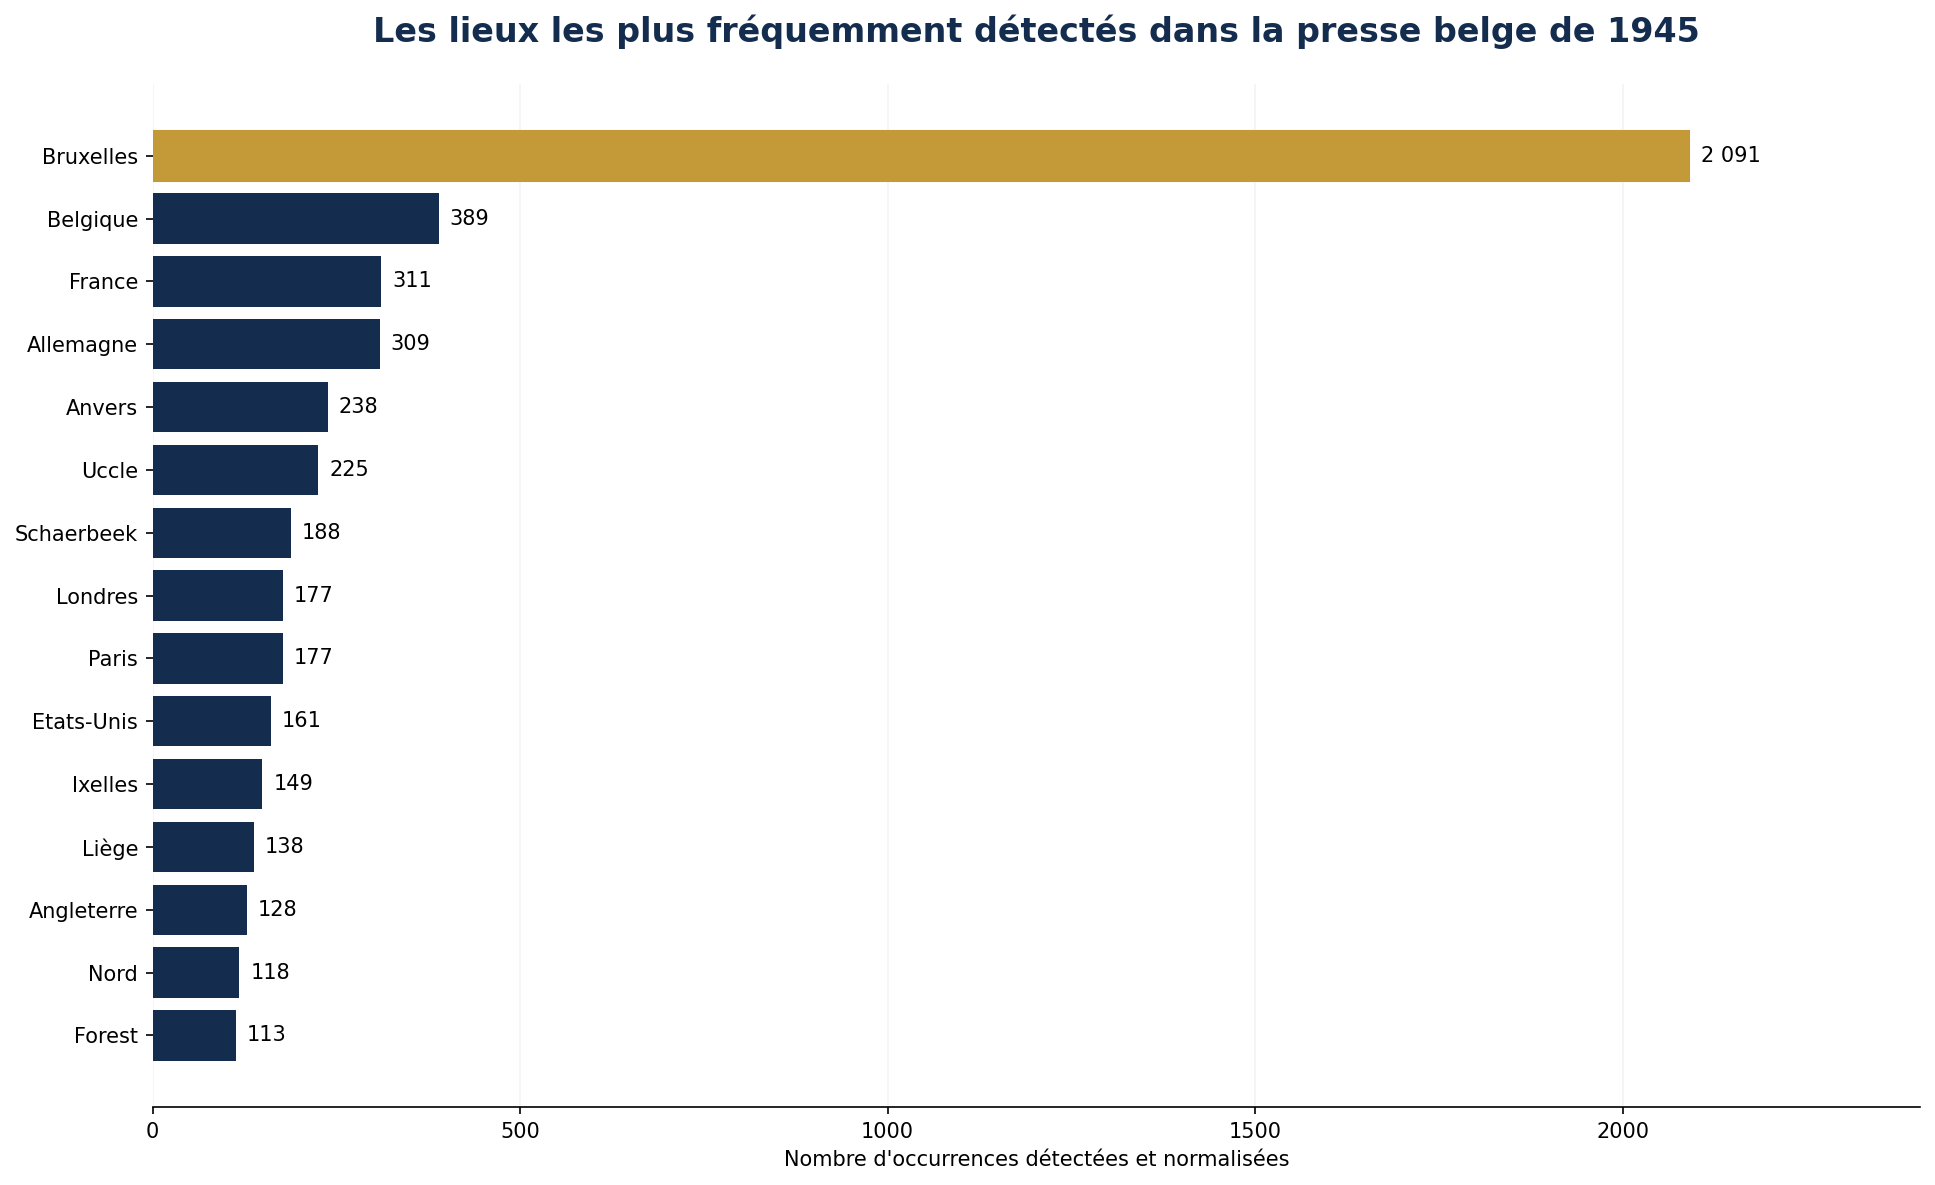

Graphique enregistré : ../../data/tmp/lieux_1945_spacy.png


In [26]:
import matplotlib.pyplot as plt
import os

# Sélectionner les 15 lieux les plus fréquents
top_lieux = lieux_nettoyes.most_common(15)

noms = [lieu for lieu, nombre in top_lieux]
valeurs = [nombre for lieu, nombre in top_lieux]

# Créer le graphique
fig, ax = plt.subplots(figsize=(13, 8), dpi=150)

barres = ax.barh(
    noms[::-1],
    valeurs[::-1],
    color="#142D4E"
)

# Mettre Bruxelles en évidence
barres[-1].set_color("#C49A38")

# Ajouter les valeurs
for barre in barres:
    largeur = barre.get_width()
    ax.text(
        largeur + 15,
        barre.get_y() + barre.get_height() / 2,
        f"{int(largeur):,}".replace(",", " "),
        va="center",
        fontsize=10
    )

ax.set_title(
    "Les lieux les plus fréquemment détectés dans la presse belge de 1945",
    fontsize=16,
    fontweight="bold",
    color="#142D4E",
    pad=20
)

ax.set_xlabel("Nombre d'occurrences détectées et normalisées")
ax.set_xlim(0, max(valeurs) * 1.15)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

# Enregistrer le graphique
output_path = "../../data/tmp/lieux_1945_spacy.png"
os.makedirs(os.path.dirname(output_path), exist_ok=True)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", output_path)

In [28]:
from collections import defaultdict

# Compter les personnes reconnues dans le corpus de 1945
people = defaultdict(int)

for (entite, categorie), nombre in entites_corpus.items():

    if categorie == "PER" and len(entite) > 3:
        people[entite] += nombre

print("Nombre de noms distincts détectés :", len(people))

Nombre de noms distincts détectés : 20529


In [29]:
# Trier les personnes par fréquence décroissante
sorted_people = sorted(
    people.items(),
    key=lambda kv: kv[1],
    reverse=True
)

# Afficher les 30 premières personnes
for person, freq in sorted_people[:30]:
    print(f"{person} apparaît {freq} fois dans le corpus")

Rossel apparaît 1937 fois dans le corpus
Ecrire Ag apparaît 229 fois dans le corpus
Louise apparaît 113 fois dans le corpus
Hitler apparaît 110 fois dans le corpus
Agence Rossel apparaît 100 fois dans le corpus
Rosse apparaît 97 fois dans le corpus
Laval apparaît 86 fois dans le corpus
trav apparaît 83 fois dans le corpus
M. Churchill apparaît 75 fois dans le corpus
atel apparaît 73 fois dans le corpus
Pétain apparaît 69 fois dans le corpus
général de Gaulle apparaît 51 fois dans le corpus
M. Van Acker apparaît 50 fois dans le corpus
Léopold apparaît 47 fois dans le corpus
Brugmann apparaît 46 fois dans le corpus
g. Rossel apparaît 45 fois dans le corpus
Rapp apparaît 45 fois dans le corpus
culs apparaît 44 fois dans le corpus
Monsieur apparaît 42 fois dans le corpus
Réun apparaît 40 fois dans le corpus
A. P. apparaît 40 fois dans le corpus
M. Spaak apparaît 39 fois dans le corpus
chamb apparaît 37 fois dans le corpus
Jette apparaît 36 fois dans le corpus
A. F. P. apparaît 36 fois dans

In [30]:
from collections import Counter

# Expressions problématiques identifiées dans les résultats
personnes_exclues = {
    "rossel",
    "ecrire ag",
    "agence rossel",
    "rosse",
    "trav",
    "atel",
    "g. rossel",
    "rapp",
    "culs",
    "monsieur",
    "réun",
    "chamb",
    "comptab",
    "a. p.",
    "a. f. p.",
    "a.f.p."
}

# Conserver les prédictions PER non exclues
personnes_filtrees = Counter({
    nom: nombre
    for nom, nombre in people.items()
    if nom.strip().lower() not in personnes_exclues
})

print("Les 25 personnes les plus fréquentes après filtrage :\n")

for nom, nombre in personnes_filtrees.most_common(25):
    print(f"{nom} : {nombre}")

Les 25 personnes les plus fréquentes après filtrage :

Louise : 113
Hitler : 110
Laval : 86
M. Churchill : 75
Pétain : 69
général de Gaulle : 51
M. Van Acker : 50
Léopold : 47
Brugmann : 46
M. Spaak : 39
Jette : 36
Jardin : 36
Reine : 34
Hardy : 32
récomp : 30
conn : 30
Dansaert : 30
Staline : 30
Président : 29
Jard : 28
Ec Ag : 28
Van Acker : 26
Roasel : 25
Molière : 25
Roosevelt : 25


In [31]:
# Examiner des extraits du corpus autour de certains noms
noms_a_verifier = [
    "Hitler",
    "Laval",
    "Churchill",
    "Pétain",
    "de Gaulle",
    "Van Acker",
    "Spaak"
]

for nom in noms_a_verifier:
    print(f"\n===== {nom} =====")

    exemples = 0

    for texte in textes_1945:
        position = texte.lower().find(nom.lower())

        if position != -1:
            debut = max(0, position - 100)
            fin = min(len(texte), position + len(nom) + 100)

            extrait = texte[debut:fin].replace("\n", " ")
            print(extrait)
            print("-" * 50)

            exemples += 1

        if exemples == 2:
            break


===== Hitler =====
 fut enclin à considérer ce volume trop dense comme un pamphlet écrit par un ancien collaborateur d’Hitler, qui fut, en 1933, pré- sidept du Sénat de Dantzig et qui dut s’enfuir à l’étranger en 1935. Rausch
--------------------------------------------------
La taxe sur l’alcool sera portée à 1,000 fr. par hectolitre. (A. F. P.). Bruits bizarres au sujet d’Hitler Les bruits les plus bizarres circulent à Stockholm au sujet d’Hitler. Le correspondant à Berlin du 
--------------------------------------------------

===== Laval =====
 DEM; mécaniciennes, finisseuses, ôoupènrs machine,' téglèurs, ' Vérlflcat. Bons sâ!alr.' 52, r; A. Lavallée, 52. ‘57I34A lÉfsJ. MORIAMK 67, Bd lu Révision, déin; .:'J<i«» gens et iensies (itlès de 15 à 20
--------------------------------------------------
fectionné les méthodes, alitent aux hommes d'Etat qui y entrent le maximum de confort. Quand Pierre Laval a pris place dans sa cellule ahdalouse, il s'est approché de son poste de radio, p

In [32]:
# Examiner le contexte des entités reconnues comme personnes
noms_a_verifier = [
    "Hitler",
    "Laval",
    "Churchill",
    "Pétain",
    "de Gaulle",
    "Van Acker",
    "Spaak"
]

for nom in noms_a_verifier:
    print(f"\n===== {nom} =====")

    compteur = 0

    for ent in doc_1945.ents:

        if ent.label_ == "PER" and nom.lower() in ent.text.lower():

            debut = max(0, ent.start_char - 100)
            fin = min(len(doc_1945.text), ent.end_char + 100)

            contexte = doc_1945.text[debut:fin].replace("\n", " ")

            print("Entité détectée :", ent.text)
            print("Contexte :", contexte)
            print("-" * 50)

            compteur += 1

            if compteur == 3:
                break

    if compteur == 0:
        print("Aucune occurrence PER trouvée dans ce document.")


===== Hitler =====
Aucune occurrence PER trouvée dans ce document.

===== Laval =====
Aucune occurrence PER trouvée dans ce document.

===== Churchill =====
Aucune occurrence PER trouvée dans ce document.

===== Pétain =====
Aucune occurrence PER trouvée dans ce document.

===== de Gaulle =====
Aucune occurrence PER trouvée dans ce document.

===== Van Acker =====
Aucune occurrence PER trouvée dans ce document.

===== Spaak =====
Aucune occurrence PER trouvée dans ce document.


In [33]:
# Vérifier les personnalités historiques dans les 100 documents

noms_a_verifier = [
    "Hitler",
    "Laval",
    "Churchill",
    "Pétain",
    "de Gaulle",
    "Van Acker",
    "Spaak"
]

# Maximum 2 exemples par personnalité
exemples = {nom: 0 for nom in noms_a_verifier}

for doc in nlp.pipe(textes_1945, batch_size=2):

    for ent in doc.ents:

        if ent.label_ != "PER":
            continue

        for nom in noms_a_verifier:

            if nom.lower() in ent.text.lower() and exemples[nom] < 2:

                debut = max(0, ent.start_char - 100)
                fin = min(len(doc.text), ent.end_char + 100)

                contexte = doc.text[debut:fin].replace("\n", " ")

                print(f"\n===== {nom} =====")
                print("Entité reconnue :", ent.text)
                print("Contexte :", contexte)
                print("-" * 60)

                exemples[nom] += 1

    # Arrêter lorsque tous les noms ont 2 exemples
    if all(nombre >= 2 for nombre in exemples.values()):
        break


===== Hitler =====
Entité reconnue : Hitler
Contexte :  fut enclin à considérer ce volume trop dense comme un pamphlet écrit par un ancien collaborateur d’Hitler, qui fut, en 1933, pré- sidept du Sénat de Dantzig et qui dut s’enfuir à l’étranger en 1935. Rausch
------------------------------------------------------------

===== Hitler =====
Entité reconnue : Hitler
Contexte : nq dernières années prouvent que Rauschning a vu juste, et que son réquisitoire ' implacable contre Hitler et le nazisme est fondé. Il trouve, dans les faits, une confirmation éclatante. ' . Il faut relire,
------------------------------------------------------------

===== Churchill =====
Entité reconnue : Churchill
Contexte : Act. CENTURY : Blanche Neige et le» sept nain». CHURCHILL : A Passant, de F. Capra. CINE AC Centre: Churchill, l’homme. Doc. CINEAC Nord: Pipeline et Documentaire. CINËMONDE: Ta verse do la Jamaïque. En a. (TV
------------------------------------------------------------

===== Churchill ==

In [27]:
type(doc)

spacy.tokens.doc.Doc

In [7]:
doc.text

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [8]:
doc.to_json()

{'text': 'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars',
 'ents': [{'start': 0, 'end': 5, 'label': 'ORG'}],
 'sents': [{'start': 0, 'end': 72}],
 'tokens': [{'id': 0,
   'start': 0,
   'end': 5,
   'tag': 'PROPN',
   'pos': 'PROPN',
   'morph': 'Gender=Masc|Number=Sing',
   'lemma': 'Apple',
   'dep': 'nsubj',
   'head': 1},
  {'id': 1,
   'start': 6,
   'end': 13,
   'tag': 'VERB',
   'pos': 'VERB',
   'morph': 'Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbForm=Fin',
   'lemma': 'cherche',
   'dep': 'ROOT',
   'head': 1},
  {'id': 2,
   'start': 14,
   'end': 15,
   'tag': 'ADP',
   'pos': 'ADP',
   'morph': '',
   'lemma': 'à',
   'dep': 'mark',
   'head': 3},
  {'id': 3,
   'start': 16,
   'end': 23,
   'tag': 'VERB',
   'pos': 'VERB',
   'morph': 'VerbForm=Inf',
   'lemma': 'acheter',
   'dep': 'xcomp',
   'head': 1},
  {'id': 4,
   'start': 24,
   'end': 27,
   'tag': 'DET',
   'pos': 'DET',
   'morph': 'Definite=Ind|Gender=Fem|Number=Sing|PronType=Art'

In [9]:
# Appliquer le test sur toutes les phrases
for sent in sentences:
    doc = nlp(sent)
    entities = []
    for ent in doc.ents:
        entities.append(f"{ent.text} ({ent.label_})")
    if entities:
        print(f"'{doc.text}' contient les entités suivantes : {', '.join(entities)}")
    else:
        print(f"'{doc.text}' ne contient aucune entité")

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars' contient les entités suivantes : Apple (ORG)
'Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs' ne contient aucune entité
'San Francisco envisage d'interdire les robots coursiers sur les trottoirs' contient les entités suivantes : San Francisco (LOC)
'Londres est une grande ville du Royaume-Uni' contient les entités suivantes : Londres (LOC), Royaume-Uni (LOC)
'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe' contient les entités suivantes : L’Italie (LOC), ArcelorMittal (ORG), Europe (LOC)
'Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon' contient les entités suivantes : Apple (ORG), HomePod (MISC), Echo (ORG), Amazon (ORG)
'La France ne devrait pas manquer d'électricité cet été, même en cas de canicule' contient les entités suivantes : La France (LOC)
'Nouvelles attaques de Trump contre le maire de Londres' contient les en

## Appliquer la reconnaissance d'entités nommées sur notre corpus

In [11]:
# Charger le texte
n=1000000
text = open("../data/all.txt", encoding='utf-8').read()[:n]

In [12]:
%%time
# Traiter le texte

doc = nlp(text)

CPU times: total: 46.6 s
Wall time: 46.8 s


In [14]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1

In [16]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Thérèse apparait 28 fois dans le corpus
Guilbert apparait 22 fois dans le corpus
M. Wilson apparait 20 fois dans le corpus
Daubrac apparait 20 fois dans le corpus
Gioconda apparait 19 fois dans le corpus
Rossel apparait 19 fois dans le corpus
Enguerrand apparait 17 fois dans le corpus
Wilson apparait 15 fois dans le corpus
Molière apparait 15 fois dans le corpus
Parentis apparait 13 fois dans le corpus
Edwige apparait 13 fois dans le corpus
Savinien apparait 13 fois dans le corpus
Octave apparait 12 fois dans le corpus
Monsieur apparait 12 fois dans le corpus
Grippe-Soleil apparait 11 fois dans le corpus
duc d’Aumale apparait 11 fois dans le corpus
Réclames apparait 10 fois dans le corpus
Reine apparait 10 fois dans le corpus
Ambassadeurs apparait 10 fois dans le corpus
Jules Ferry apparait 9 fois dans le corpus
Monseigneur apparait 9 fois dans le corpus
Agence Rossel apparait 8 fois dans le corpus
Henri apparait 8 fois dans le corpus
Finet apparait 7 fois dans le corpus
M. Graux appar

Exercice: essayez de lister les lieux (LOC) et les organisations (ORG) les plus mentionnées dans le corpus

In [34]:
from collections import Counter

# Compter les organisations détectées par spaCy
organisations = Counter()

for (entite, categorie), nombre in entites_corpus.items():
    if categorie == "ORG" and len(entite.strip()) > 3:
        organisations[entite.strip()] += nombre

# Trier et afficher les 30 organisations les plus fréquentes
print("Les 30 organisations les plus fréquentes :\n")

for organisation, nombre in organisations.most_common(30):
    print(f"{organisation} : {nombre}")

Les 30 organisations les plus fréquentes :

Reuter : 133
Agence Rossel : 112
Conseil : 104
Chambre : 85
trav : 61
K ON DEM : 59
GALERIES : 57
Parlement : 53
K DEM : 52
Gestapo : 51
Téléphone : 50
Inst : 46
Sénat : 42
Rosseï : 41
exlg : 38
Havas : 36
Import : 35
Ford : 34
Orchestre : 29
AGENCE : 29
Justice : 28
Reich : 27
Citroën : 26
FIRME : 26
LEOPOLD : 26
Référ : 25
ministre des Affaires étrangères : 25
Chevrolet : 23
CASIMIR : 23
CREDIT : 22


In [35]:
# Organisations sélectionnées pour une analyse qualitative
organisations_a_examiner = [
    "Reuter",
    "Agence Rossel",
    "Parlement",
    "Gestapo",
    "Sénat",
    "Havas",
    "Ford",
    "Citroën",
    "Chevrolet"
]

print("Organisations sélectionnées :\n")

for nom in organisations_a_examiner:
    print(f"{nom} : {organisations.get(nom, 0)} occurrences")

Organisations sélectionnées :

Reuter : 133 occurrences
Agence Rossel : 112 occurrences
Parlement : 53 occurrences
Gestapo : 51 occurrences
Sénat : 42 occurrences
Havas : 36 occurrences
Ford : 34 occurrences
Citroën : 26 occurrences
Chevrolet : 23 occurrences
